# Was Blake Bortles Holding the Jaguars Back?

**A look at Bortles' game-by-game numbers, 2014–2018**

Blake Bortles has a reputation as a mediocre quarterback, yet he led the Jacksonville Jaguars to the AFC Championship game in 2017, one win away from the Super Bowl. That raises a question: *was Bortles always a decent quarterback held back by a weak team, or did the 2017 Jaguars succeed in spite of him?*

To explore it, I compare Bortles' 2017 season against the other seasons he started, using game-level team statistics.

**Data:** about 4,500 NFL games from 2002–2018, scraped from ESPN and shared on [r/datasets](https://www.reddit.com/r/datasets/comments/djucb6/nfl_game_stats_scraped_from_espn/). Each row is one game, with stats for both the home and away team.

**Short version:** 2017 was clearly Bortles' best year at avoiding sacks, but his passing yardage did not jump that year, so the 2017 run doesn't look like it came from a passing breakout. The [takeaways](#Takeaways) section has the details and caveats.

## 1. Setup

The data comes as a CSV with one row per game. A few columns store two numbers in one string (for example, a third-down record of `4-12` means 4 conversions on 12 attempts). I load those columns as plain text so pandas doesn't mistake values like `4-12` for dates.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Columns stored as "made-attempted" style strings; read them as text
dash_columns = ['third_downs_away', 'third_downs_home',
                'comp_att_away', 'comp_att_home',
                'sacks_away', 'sacks_home']

nfl_df = pd.read_csv("NFL.csv", dtype={col: str for col in dash_columns})

Since those columns hold two values each, I wrote two small helpers to pull out the part before and after the dash.

In [2]:
def before_dash(text):
    """'4-12' -> 4.0"""
    return float(text.split("-")[0])

def after_dash(text):
    """'4-12' -> 12.0"""
    return float(text.split("-")[1])

## 2. Choosing the games to study

### Picking the right measures of quarterback play
The dataset records team stats, not individual player stats, so I need team-level measures that mostly reflect quarterback play:

- **Third-down conversion rate:** how often the offense keeps the drive alive on third down
- **Completion percentage:** completed passes divided by attempted passes
- **Passing yards per game**
- **Sacks taken per game:** how often the quarterback was tackled behind the line while trying to pass
- **Interceptions thrown per game**

Some of these depend on teammates too, such as a receiver dropping a pass or the offensive line failing to block. I'm treating them as rough proxies for quarterback performance, not clean measurements of Bortles alone.

One stat I had to leave out is rushing. Bortles ran the ball a lot, but the dataset doesn't separate quarterback runs from running-back runs, so including rushing would blur the picture.

### Keeping only games Bortles started
I want only the games where Bortles was the starting quarterback. First, all Jaguars games (home or away):

In [3]:
jags_df = nfl_df[(nfl_df["home"] == "Jaguars") | (nfl_df["away"] == "Jaguars")]

Bortles was drafted in 2014 and his last season with the Jaguars was 2018, so I keep those five seasons. He did not start the first three games of 2014, so I skip those with `iloc[3:]`.

In [4]:
bort_df = jags_df[jags_df["Season"].between(2014, 2018)]
bort_df = bort_df.iloc[3:]

He also missed a few later games. The dataset has no player information, so I dropped those games by their row labels. Here is what they are:

In [5]:
missed_game_ids = [4453, 4461, 4487]
jags_df.loc[missed_game_ids, ["date", "away", "home", "Season"]]

,date,away,home,Season
4453,12/2/2018,Colts,Jaguars,2018
4461,12/6/2018,Jaguars,Titans,2018
4487,12/16/2018,Redskins,Jaguars,2018


In [ ]:
bort_df = bort_df.drop(index=missed_game_ids).copy()
len(bort_df)

Note that these games include both regular-season and playoff games.

## 3. Building the Jaguars-side stats

Each row has separate columns for the home and away team, and the Jaguars are sometimes one and sometimes the other. For each stat, I pick whichever side belongs to the Jaguars.

In [6]:
is_home = bort_df["home"] == "Jaguars"

def jags_side(home_values, away_values):
    """Pick the Jaguars' number from each game, whether they were home or away."""
    return np.where(is_home, home_values, away_values)

Now I build the five measures. Third downs and completions are stored as "made-attempted", so I split them and turn them into percentages. Sacks are stored as "number-yards", and I keep only the number of sacks since yards lost won't matter for this question.

In [7]:
# Third downs: conversions and attempts
third_made = jags_side(bort_df["third_downs_home"].apply(before_dash),
                       bort_df["third_downs_away"].apply(before_dash))
third_tried = jags_side(bort_df["third_downs_home"].apply(after_dash),
                        bort_df["third_downs_away"].apply(after_dash))

# Passing: completions and attempts
comp_made = jags_side(bort_df["comp_att_home"].apply(before_dash),
                      bort_df["comp_att_away"].apply(before_dash))
comp_tried = jags_side(bort_df["comp_att_home"].apply(after_dash),
                       bort_df["comp_att_away"].apply(after_dash))

bort_df["third_down_pct"] = third_made / third_tried
bort_df["pass_pct"] = comp_made / comp_tried
bort_df["pass_yards"] = jags_side(bort_df["passing_yards_home"],
                                  bort_df["passing_yards_away"]).astype(float)
bort_df["interceptions"] = jags_side(bort_df["int_home"],
                                     bort_df["int_away"]).astype(float)
bort_df["sacks_taken"] = jags_side(bort_df["sacks_home"].apply(before_dash),
                                   bort_df["sacks_away"].apply(before_dash))

## 4. Season-by-season comparison

To see whether 2017 stands out, I average each measure over all the games in a season.

In [8]:
stat_cols = ["third_down_pct", "pass_pct", "pass_yards",
             "sacks_taken", "interceptions"]
season_summary = bort_df.groupby("Season")[stat_cols].mean()

# Friendlier labels for display
season_summary.rename(columns={
    "third_down_pct": "Third-Down Conversion Rate",
    "pass_pct": "Completion Percentage",
    "pass_yards": "Passing Yards per Game",
    "sacks_taken": "Sacks Taken per Game",
    "interceptions": "Interceptions per Game",
}).round(3)

,Third-Down Conversion Rate,Completion Percentage,Passing Yards per Game,Sacks Taken per Game,Interceptions per Game
Season,,,,,
2014,0.327,0.586,184.385,4.154,1.154
2015,0.341,0.586,256.750,3.188,1.125
2016,0.342,0.584,233.000,2.125,1.000
2017,0.370,0.594,218.684,1.526,0.684
2018,0.398,0.612,194.312,3.312,0.812


The table is useful for precise values, but trends are easier to see in a chart. I'll plot the two measures that I found most interesting: passing yards and sacks. The dashed line marks 2017.

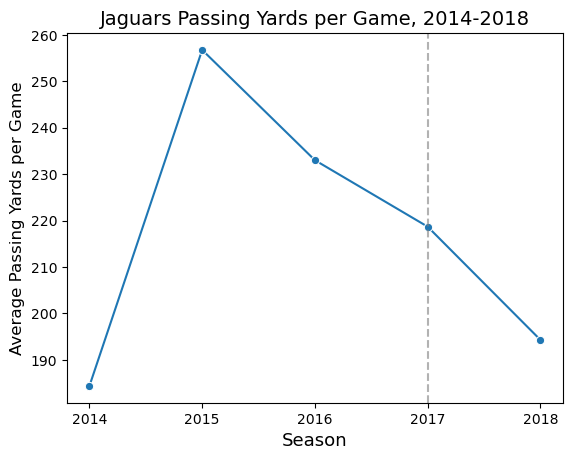

In [9]:
def plot_season_trend(column, ylabel, title):
    ax = sns.lineplot(data=season_summary.reset_index(),
                      x="Season", y=column, marker="o")
    ax.set_xticks(range(2014, 2019))
    ax.axvline(2017, linestyle="--", color="gray", alpha=0.6)
    plt.xlabel("Season", fontsize=13)
    plt.ylabel(ylabel, fontsize=12)
    plt.title(title, fontsize=14)
    plt.show()

plot_season_trend("pass_yards", "Average Passing Yards per Game",
                  "Jaguars Passing Yards per Game, 2014-2018")

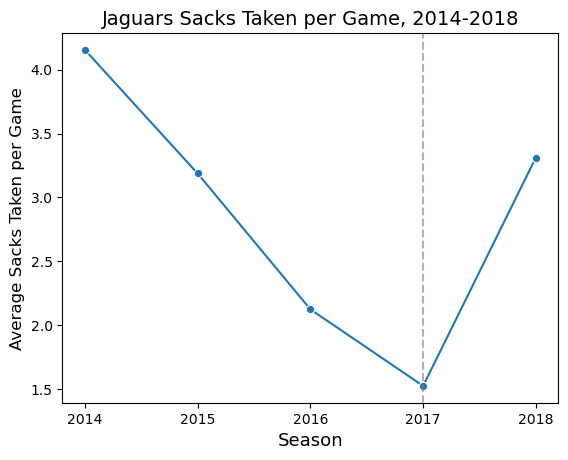

In [10]:
plot_season_trend("sacks_taken", "Average Sacks Taken per Game",
                  "Jaguars Sacks Taken per Game, 2014-2018")

## Takeaways

- **Sacks:** 2017 was Bortles' best season at avoiding sacks, at about 1.5 per game versus roughly 2 to 4 in every other season. Sacks come from the offensive line as well as the quarterback, so this could reflect better protection, quicker throws, or both.
- **Passing yards:** 2017 was not a passing breakout. Average passing yards in 2017 (about 219 per game) were lower than in 2015 and 2016, and fell again in 2018. The AFC Championship run does not appear to have come from throwing the ball more productively.
- **Third downs:** Third-down conversion rate climbed steadily over the five seasons, from about 33% in 2014 to about 42% in 2018. 2017 sits in the middle of that trend rather than standing out.

**In Conclusion:** the evidence is mixed. 2017 doesn't show a jump in passing production, which is consistent with the idea that the Jaguars did well in spite of Bortles' passing rather than because of it. But he did take far fewer sacks that year, so he was not simply bad in every respect.

### Limitations
- These are **team** statistics, so they can't fully separate Bortles from his offensive line, receivers, or play-calling.
- Each season has only about 16 games, so season averages can shift a lot from one or two unusual games. 2017 also includes playoff games.
- I haven't looked at the defense or running game, which likely mattered to the 2017 team's success. A natural next step would be to compare those against the passing numbers.